### Part A

In [3]:
import os
import numpy as np
from PIL import Image
from sklearn.model_selection import train_test_split

dataset_path = 'archive7'

X_list = []
y_list = []
images_2d_list = []

# 1. Read local images, flatten them, and create the label array
for subject_id in range(1, 41):
    subject_folder = os.path.join(dataset_path, f's{subject_id}')
    
    if not os.path.exists(subject_folder):
        continue
        
    for img_num in range(1, 11):
        img_path = os.path.join(subject_folder, f'{img_num}.pgm')
        
        if os.path.exists(img_path):
            # Read image and ensure grayscale
            img = Image.open(img_path).convert('L')
            img_array = np.array(img)
            
            # Store 2D matrix, flatten for feature vector, and store label (0-indexed)
            images_2d_list.append(img_array)
            X_list.append(img_array.flatten())
            y_list.append(subject_id - 1)

# Convert lists to NumPy arrays
images_2d = np.array(images_2d_list)
X = np.array(X_list)
y = np.array(y_list)

# 2. Inspect dimensions and intensity values
n_samples, height, width = images_2d.shape
n_features = X.shape[1]

print("--- Local Image Representation & Inspection ---")
print(f"Total images: {n_samples}")
print(f"Original image dimensions: {height}x{width} pixels")
print(f"Flattened feature vector size: {n_features}")
print(f"Min intensity: {images_2d.min()} | Max intensity: {images_2d.max()}")
print(f"Total unique subjects: {len(np.unique(y))}\n")

# 3. Create a reproducible, stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    stratify=y, 
    random_state=42
)

print("--- Train-Test Split ---")
print(f"Training set: {X_train.shape[0]} images ({X_train.shape[0]} x {X_train.shape[1]} matrix)")
print(f"Testing set: {X_test.shape[0]} images ({X_test.shape[0]} x {X_test.shape[1]} matrix)")
print(f"Unique subjects in train: {len(np.unique(y_train))}/40 | In test: {len(np.unique(y_test))}/40")

--- Local Image Representation & Inspection ---
Total images: 400
Original image dimensions: 112x92 pixels
Flattened feature vector size: 10304
Min intensity: 0 | Max intensity: 251
Total unique subjects: 40

--- Train-Test Split ---
Training set: 320 images (320 x 10304 matrix)
Testing set: 80 images (80 x 10304 matrix)
Unique subjects in train: 40/40 | In test: 40/40


### Part B

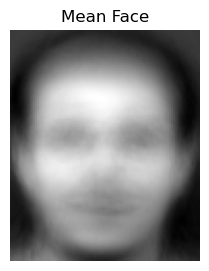


Computing Principal Directions...
Eigendecomposition Time: 75.0857 seconds
SVD Time: 0.2343 seconds

Comparison:
SVD is generally faster and more numerically stable than computing the full covariance matrix, especially when the number of features (pixels) heavily outnumbers the number of samples.

Minimum components to preserve >= 90% variance: 98


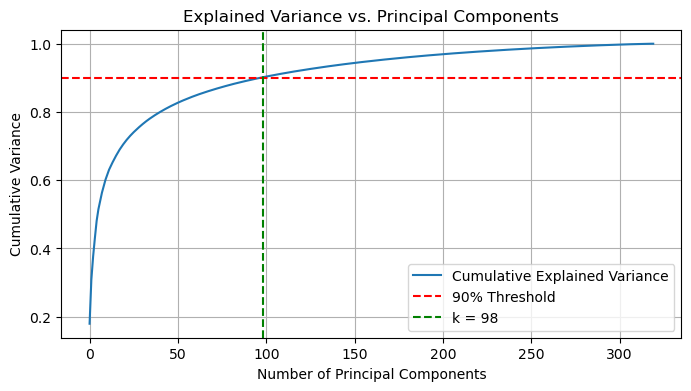

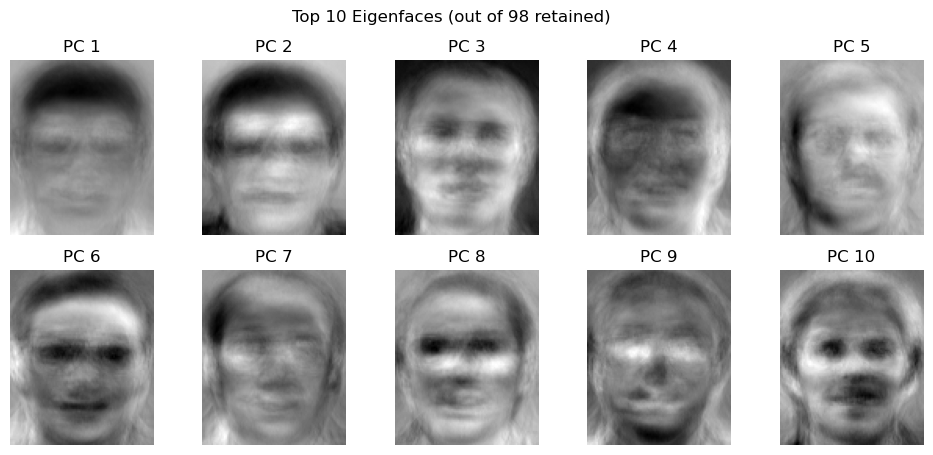

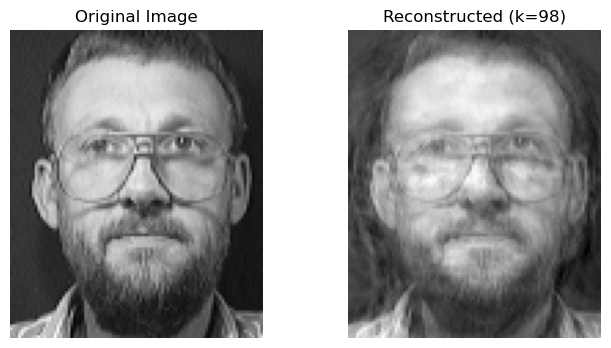


--- Storage & Reconstruction Comparison ---
Original Storage (Training): 3297280 parameters
Reduced Storage (Training): 1051456 parameters
Compression Ratio: 3.14x
Quality: The reconstructed images lose high-frequency details (appearing slightly blurred) but retain the core structural features necessary for facial recognition, successfully filtering out noise.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import time

# 1. Compute Mean Face & Center the Data

mean_face = np.mean(X_train, axis=0)
X_train_centered = X_train - mean_face
X_test_centered = X_test - mean_face

# Visualize the mean face
plt.figure(figsize=(3, 3))
plt.imshow(mean_face.reshape(height, width), cmap='gray')
plt.title("Mean Face")
plt.axis('off')
plt.show()

# 2. Covariance/Eigendecomposition vs SVD

print("\nComputing Principal Directions...")

# Approach A: Covariance Matrix & Eigendecomposition
start_time = time.time()
# Using rowvar=False because variables (pixels) are columns
cov_matrix = np.cov(X_train_centered, rowvar=False) 
# eigh is optimized for symmetric matrices like covariance matrices
eigenvalues_cov, eigenvectors_cov = np.linalg.eigh(cov_matrix)
# Sort in descending order
idx = np.argsort(eigenvalues_cov)[::-1]
eigenvalues_cov = eigenvalues_cov[idx]
eigenvectors_cov = eigenvectors_cov[:, idx]
time_eig = time.time() - start_time
print(f"Eigendecomposition Time: {time_eig:.4f} seconds")

# Approach B: Singular Value Decomposition (SVD)
start_time = time.time()
# SVD directly on centered data: X = U * S * V^T
U, S, Vt = np.linalg.svd(X_train_centered, full_matrices=False)
# Eigenvalues are related to singular values by: eig_val = (S^2) / (n_samples - 1)
eigenvalues_svd = (S ** 2) / (X_train_centered.shape[0] - 1)
eigenvectors_svd = Vt.T 
time_svd = time.time() - start_time
print(f"SVD Time: {time_svd:.4f} seconds")

print("\nComparison:")
print("SVD is generally faster and more numerically stable than computing the full covariance matrix, "
      "especially when the number of features (pixels) heavily outnumbers the number of samples.")

# 3. Explained Variance & Retaining Components
total_variance = np.sum(eigenvalues_svd)
explained_variance_ratio = eigenvalues_svd / total_variance
cumulative_variance = np.cumsum(explained_variance_ratio)

# Find minimum components for 90% variance
k_90 = np.argmax(cumulative_variance >= 0.90) + 1
print(f"\nMinimum components to preserve >= 90% variance: {k_90}")

plt.figure(figsize=(8, 4))
plt.plot(cumulative_variance, label='Cumulative Explained Variance')
plt.axhline(y=0.90, color='r', linestyle='--', label='90% Threshold')
plt.axvline(x=k_90, color='g', linestyle='--', label=f'k = {k_90}')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Variance')
plt.title('Explained Variance vs. Principal Components')
plt.legend()
plt.grid(True)
plt.show()

# 4. Visualize Eigenfaces
# Retain top k components
top_k_eigenvectors = eigenvectors_svd[:, :k_90]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
fig.suptitle(f"Top 10 Eigenfaces (out of {k_90} retained)")
for i, ax in enumerate(axes.flat):
    eigenface = top_k_eigenvectors[:, i].reshape(height, width)
    ax.imshow(eigenface, cmap='gray')
    ax.set_title(f"PC {i+1}")
    ax.axis('off')
plt.show()

# 5. Project Faces & Reconstruct

X_train_pca = np.dot(X_train_centered, top_k_eigenvectors)
X_test_pca = np.dot(X_test_centered, top_k_eigenvectors)

# Reconstruct back to the original pixel space
# X_reconstructed = (X_pca * V^T) + mean_face
X_train_reconstructed = np.dot(X_train_pca, top_k_eigenvectors.T) + mean_face

# Visualize original vs reconstructed
sample_idx = 0
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(X_train[sample_idx].reshape(height, width), cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(X_train_reconstructed[sample_idx].reshape(height, width), cmap='gray')
axes[1].set_title(f"Reconstructed (k={k_90})")
axes[1].axis('off')
plt.show()

# 6. Storage & Quality Comparison
original_storage = X_train.shape[0] * X_train.shape[1]

reduced_storage = (X_train.shape[0] * k_90) + (X_train.shape[1] * k_90) + X_train.shape[1]
compression_ratio = original_storage / reduced_storage

print("\ Storage & Reconstruction Comparison")
print(f"Original Storage (Training): {original_storage} parameters")
print(f"Reduced Storage (Training): {reduced_storage} parameters")
print(f"Compression Ratio: {compression_ratio:.2f}x")
print("Quality: The reconstructed images lose high-frequency details (appearing slightly blurred) "
      "but retain the core structural features necessary for facial recognition, successfully filtering out noise.")

### Part C

--- Face Recognition Results ---
Features in Raw Pixel Space : 10304
Features in PCA Space (k=98) : 98
Raw Pixel 1-NN Accuracy     : 100.00%
PCA Eigenface 1-NN Accuracy  : 95.00%

Visualizing Correct Matches:


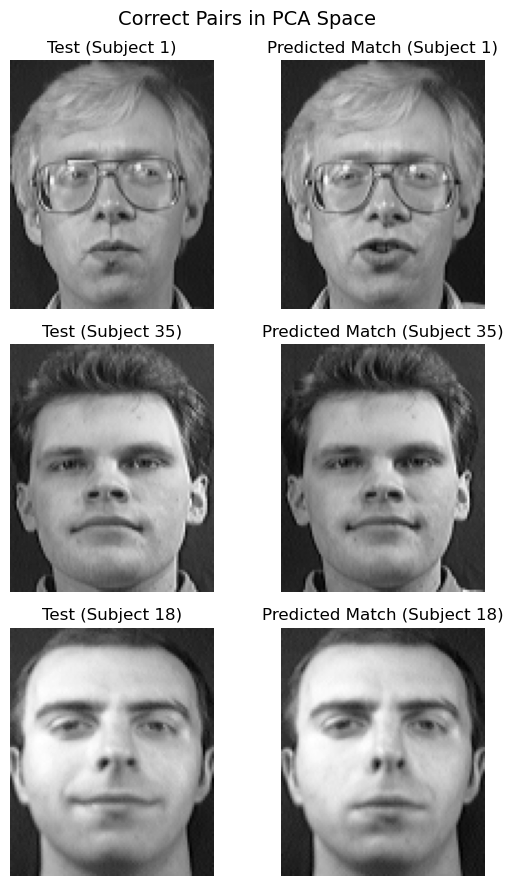


Visualizing Incorrect Matches:


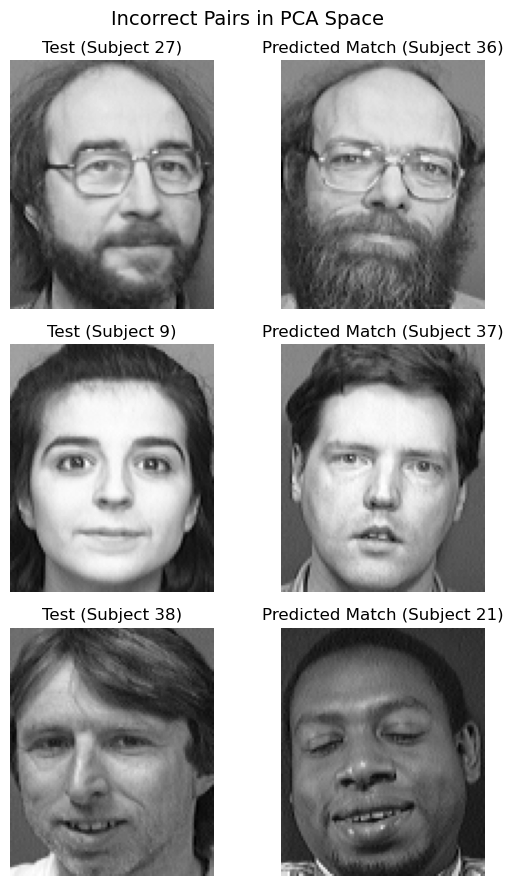

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Pure NumPy Distance-Based Nearest-Neighbor Matching Function
def nearest_neighbor_matching(train_data, test_data, train_labels):
    """
    Finds the closest training sample for each test sample using Euclidean distance.
    Computes distances purely using vector operations:
    ||a - b||_2 = sqrt(sum((a - b)^2))
    """
    predictions = []
    min_distances = []
    matched_train_indices = []

    for test_sample in test_data:
        # Broadcasting difference: (N_train, D) - (D,) -> (N_train, D)
        differences = train_data - test_sample
        # Compute Euclidean distance to every training image
        distances = np.sqrt(np.sum(differences ** 2, axis=1))
        
        # Locate closest match
        best_match_idx = np.argmin(distances)
        matched_train_indices.append(best_match_idx)
        min_distances.append(distances[best_match_idx])
        predictions.append(train_labels[best_match_idx])

    return np.array(predictions), np.array(matched_train_indices), np.array(min_distances)

# 2. Face Recognition in Reduced PCA Space

pca_preds, pca_matched_train_indices, _ = nearest_neighbor_matching(
    X_train_pca, X_test_pca, y_train
)
pca_accuracy = np.mean(pca_preds == y_test) * 100

# 3. Face Recognition using Raw Pixels (Baseline)

raw_preds, raw_matched_train_indices, _ = nearest_neighbor_matching(
    X_train, X_test, y_train
)
raw_accuracy = np.mean(raw_preds == y_test) * 100

print("--- Face Recognition Results")
print(f"Features in Raw Pixel Space : {X_train.shape[1]}")
print(f"Features in PCA Space (k={k_90}) : {X_train_pca.shape[1]}")
print(f"Raw Pixel 1-NN Accuracy     : {raw_accuracy:.2f}%")
print(f"PCA Eigenface 1-NN Accuracy  : {pca_accuracy:.2f}%")

# 4. Inspect Correct and Incorrect Matches in PCA Space
correct_indices = np.where(pca_preds == y_test)[0]
incorrect_indices = np.where(pca_preds != y_test)[0]

def plot_match_pairs(test_indices, title_prefix="Match"):
    num_plots = min(3, len(test_indices))
    if num_plots == 0:
        print(f"No samples found for {title_prefix}.")
        return

    fig, axes = plt.subplots(num_plots, 2, figsize=(6, 3 * num_plots))
    if num_plots == 1:
        axes = np.expand_dims(axes, axis=0)

    for i in range(num_plots):
        t_idx = test_indices[i]
        matched_train_idx = pca_matched_train_indices[t_idx]

        # Test Image
        axes[i, 0].imshow(X_test[t_idx].reshape(height, width), cmap='gray')
        axes[i, 0].set_title(f"Test (Subject {y_test[t_idx]})")
        axes[i, 0].axis('off')

        # Matched Training Image
        axes[i, 1].imshow(X_train[matched_train_idx].reshape(height, width), cmap='gray')
        axes[i, 1].set_title(f"Predicted Match (Subject {pca_preds[t_idx]})")
        axes[i, 1].axis('off')

    plt.suptitle(f"{title_prefix} Pairs in PCA Space", fontsize=14)
    plt.tight_layout()
    plt.show()

print("\nVisualizing Correct Matches:")
plot_match_pairs(correct_indices, title_prefix="Correct")

if len(incorrect_indices) > 0:
    print("\nVisualizing Incorrect Matches:")
    plot_match_pairs(incorrect_indices, title_prefix="Incorrect")
else:
    print("\nNo incorrect matches to display (100% accuracy achieved).")

### Part D

k Components    | Classifier                | Accuracy   | Train Time (ms)
---------------------------------------------------------------------------
98              | SVM (RBF Kernel)          |    95.00% |      37.96 ms
98              | SVM (Linear Kernel)       |    97.50% |      21.76 ms
98              | KNN (k=1)                 |    95.00% |       0.51 ms
98              | Logistic Regression       |    96.25% |      76.44 ms
---------------------------------------------------------------------------
Note: Accuracies above are shown specifically for k_90 (90% variance threshold).


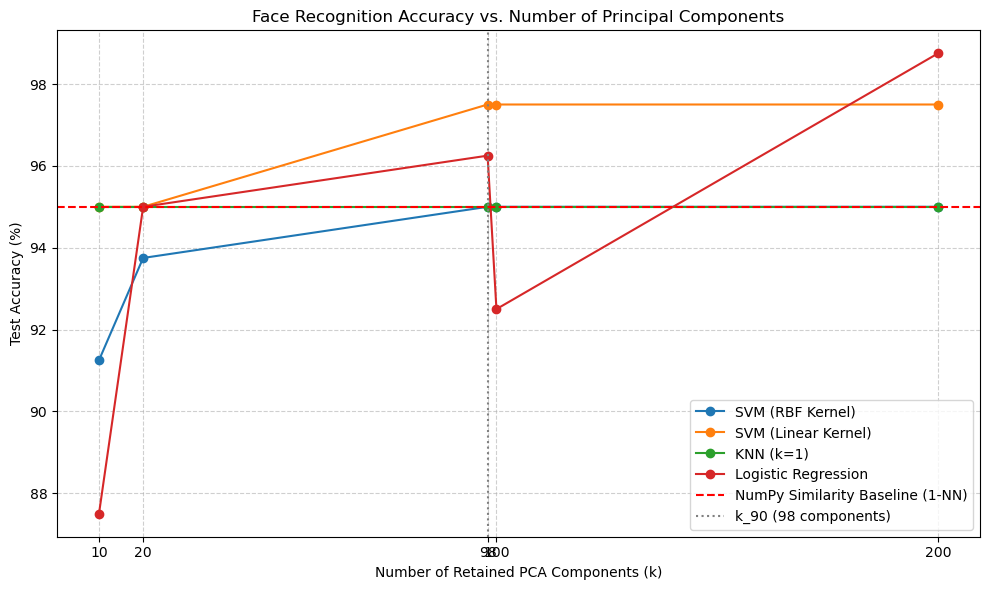

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
import time

# Define the models for comparison

classifiers = {
    "SVM (RBF Kernel)": SVC(kernel='rbf', gamma='scale', C=1.0),
    "SVM (Linear Kernel)": SVC(kernel='linear', C=1.0),
    "KNN (k=1)": KNeighborsClassifier(n_neighbors=1, metric='euclidean'),
    "Logistic Regression": LogisticRegression(max_iter=1000, solver='lbfgs')
}

# Experiment with different numbers of retained principal components
# k_90 was calculated in Part B. We test values below and above it to observe the trade-off.
k_values = [10, 20, k_90, 100, 200]
results = {name: [] for name in classifiers.keys()}
training_times = {name: [] for name in classifiers.keys()}

print(f"{'k Components':<15} | {'Classifier':<25} | {'Accuracy':<10} | {'Train Time (ms)'}")
print("-" * 75)

for k in k_values:
    # 1. Select top k principal components from our NumPy SVD/Eigendecomposition
    top_k_eigenvectors = eigenvectors_svd[:, :k]
    
    # 2. Project training and testing data into the new k-dimensional space
    X_train_pca_k = np.dot(X_train_centered, top_k_eigenvectors)
    X_test_pca_k = np.dot(X_test_centered, top_k_eigenvectors)
    
    # 3. Train and evaluate each classifier
    for name, clf in classifiers.items():
        start_time = time.perf_counter()
        clf.fit(X_train_pca_k, y_train)
        train_time_ms = (time.perf_counter() - start_time) * 1000
        
        preds = clf.predict(X_test_pca_k)
        acc = accuracy_score(y_test, preds) * 100
        
        results[name].append(acc)
        training_times[name].append(train_time_ms)
        
        if k == k_90:
            print(f"{k:<15} | {name:<25} | {acc:>8.2f}% | {train_time_ms:>10.2f} ms")

print("-" * 75)
print("Note: Accuracies above are shown specifically for k_90 (90% variance threshold).")

# Visualizing the Experiment: Accuracy vs Number of Components
plt.figure(figsize=(10, 6))

for name, acc_list in results.items():
    plt.plot(k_values, acc_list, marker='o', label=name)

# Add a horizontal line for the pure NumPy similarity baseline (computed in Part C)
# Assuming pca_acc holds the accuracy from the custom nearest_neighbor_matching function
if 'pca_acc' in locals():
    plt.axhline(y=pca_acc, color='r', linestyle='--', label='NumPy Similarity Baseline (1-NN)')

plt.axvline(x=k_90, color='gray', linestyle=':', label=f'k_90 ({k_90} components)')

plt.title('Face Recognition Accuracy vs. Number of Principal Components')
plt.xlabel('Number of Retained PCA Components (k)')
plt.ylabel('Test Accuracy (%)')
plt.xticks(k_values)
plt.legend(loc='lower right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()